
# TP Final

## Notebook 3: Comparación de modelos y selección

**Objetivo:** comparar las corridas registradas en MLflow en el notebook 2, elegir el mejor modelo y discutir las limitaciones del análisis.

##Paso 1: Tabla de corridas
Se consulta el experimento con `mlflow.search_runs` y se arma una tabla con las métricas de cada corrida, ordenada por ROC-AUC.

In [0]:
import mlflow
usuario = spark.sql("select current_user()").first()[0]
exp = mlflow.get_experiment_by_name(f"/Users/{usuario}/tp_final_vino")

runs = mlflow.search_runs(experiment_ids=[exp.experiment_id], order_by=["metrics.roc_auc DESC"])
print(len(runs), "runs")   # tienen que ser 9

tabla = runs[["tags.mlflow.runName", "params.modelo", "metrics.accuracy", "metrics.precision",
              "metrics.recall", "metrics.f1", "metrics.roc_auc", "metrics.train_roc_auc"]].round(3)
tabla.columns = ["run", "modelo", "accuracy", "precision", "recall", "f1", "roc_auc", "train_roc_auc"]
display(tabla)

{"ts": "2026-10-30 02:47:06.445", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvNDAzNTM2MTM0MDgxNTI0NBABIAEyJDAxYTE4YWIzLWViMjItNzA4Mi05NmExLTJhNmM1NmFhYWFlYjokMGZiOTFjZDItZTU5Ny0zYTMyLWI4OWItZGVlZTY3MDVkZTJkSgwImYqQ1wYQgKWftAFQAVgBYAFowfy7s/vEow2IAQA=.", "context": {}}
{"ts": "2026-10-30 02:47:06.445", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvNDAzNTM2MTM0MDgxNTI0NBABIAEyJDAxYTE4YWIzLWViMjItNzA4Mi05NmExLTJhNmM1NmFhYWFlYjokMGZiOTFjZDItZTU5Ny0zYTMyLWI4OWItZGVlZTY3MDVkZTJkSgwImYqQ1wYQgKWftAFQAVgBYAFowfy7s/vEow2IAQA=.", "context": {}}
{"ts": "2026-10-30 02:47:06.445", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvNDAzNTM2MTM0MDgxNTI0NBABIAEyJDAxYTE4YWIzLWViMjItNzA4Mi05NmExLTJhNmM1NmFhYWFlYjokMGZiOTFjZDItZTU5Ny0zYTMyLWI4OWItZGVlZTY3

9 runs


run,modelo,accuracy,precision,recall,f1,roc_auc,train_roc_auc
rf_n300_dNone,random_forest,0.809,0.831,0.807,0.819,0.905,1.0
lgbm_lr0.05_l31_n300,lightgbm,0.819,0.847,0.807,0.826,0.896,1.0
rf_n300_d10,random_forest,0.803,0.818,0.813,0.815,0.889,0.999
lgbm_lr0.05_l15_n300,lightgbm,0.809,0.831,0.807,0.819,0.883,1.0
lgbm_lr0.1_l15_n100,lightgbm,0.8,0.824,0.795,0.81,0.878,0.995
rf_n100_d5,random_forest,0.762,0.799,0.743,0.77,0.839,0.906
logistica_C0.1,logistica,0.738,0.767,0.731,0.749,0.825,0.821
logistica_C1,logistica,0.741,0.768,0.737,0.752,0.824,0.821
logistica_C10,logistica,0.744,0.773,0.737,0.754,0.824,0.822


##Paso 2: Comparación gráfica
Se grafica el ROC-AUC de test y de train de cada corrida. La diferencia entre ambos indica sobreajuste.

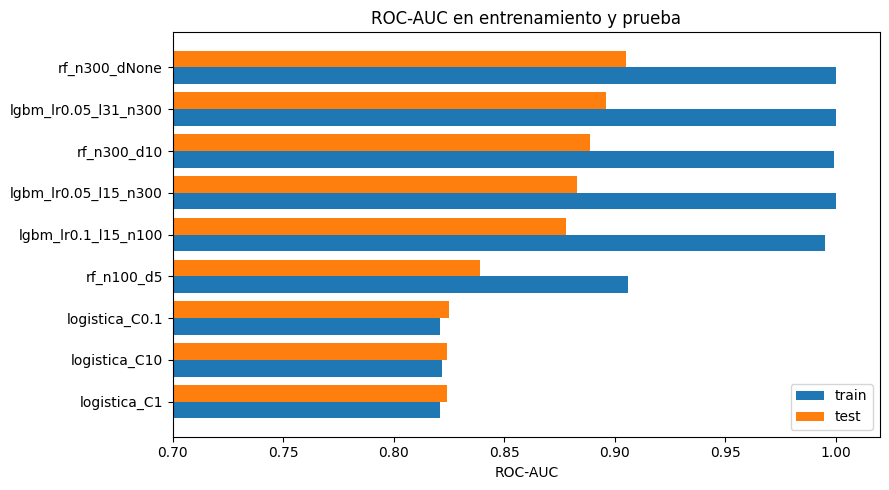

In [0]:
import matplotlib.pyplot as plt
import numpy as np

t = tabla.sort_values("roc_auc")
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y - 0.2, t["train_roc_auc"], height=0.4, label="train")
ax.barh(y + 0.2, t["roc_auc"], height=0.4, label="test")
ax.set_yticks(y); ax.set_yticklabels(t["run"])
ax.set_xlim(0.7, 1.02); ax.set_xlabel("ROC-AUC"); ax.legend()
ax.set_title("ROC-AUC en entrenamiento y prueba")
plt.tight_layout(); plt.show()

%md
**Observaciones del gráfico:**
- Los modelos de árboles tienen un ROC-AUC de prueba entre 0,88 y 0,91, bastante mayor que el de la regresión logística (≈ 0,82).
- La regresión logística rinde igual en entrenamiento y en prueba (≈ 0,82), es decir, no sobreajusta, pero es menos flexible para capturar relaciones no lineales entre las variables.
- Los modelos de árboles llegan a un ROC-AUC de entrenamiento cercano a 1, con una brecha de ~0,10 respecto del de prueba: memorizan parte de los datos de entrenamiento. Aun así, siguen rindiendo mejor en prueba que la logística.
- `rf_n100_d5` (árboles poco profundos) queda en un punto intermedio: menos sobreajuste, pero también menor rendimiento.

##Paso 3: Selección del mejor modelo
Se elige como métrica principal el **ROC-AUC de prueba**, porque no depende de un umbral de decisión y mide qué tan bien el modelo ordena los vinos buenos por encima de los no buenos. Las clases están casi balanceadas (53,5 % / 46,5 %), por lo que también se tiene en cuenta F1 y accuracy.

**Modelo elegido: `rf_n300_dNone`** (random forest, 300 árboles, sin límite de profundidad), con ROC-AUC = 0,905, F1 = 0,819 y accuracy = 0,809.


- `lgbm_lr0.05_l31_n300` es el mejor en F1 (0,826), accuracy (0,819) y precision (0,847), y queda segundo en ROC-AUC (0,896). Las diferencias con el random forest son de menos de un punto.
- Con solo 320 observaciones de prueba, esas diferencias equivalen a unos pocos vinos y no son estadísticamente distinguibles. Por eso la elección entre ambos es de criterio y no una ventaja demostrada.
- Lo que sí es claro es que los modelos de árboles superan a la regresión logística en todas las métricas.

##Paso 4: Limitaciones
- **Partición única:** se evaluó con un solo conjunto de prueba de 320 filas. No se usó validación cruzada, por lo que las métricas tienen incertidumbre y las diferencias pequeñas entre modelos no son concluyentes.
- **Duplicados:** se conservaron las 240 filas duplicadas. Hay filas de prueba también están en entrenamiento. Esto puede inflar las métricas de los modelos de árboles, que pueden memorizar esas filas (ROC-AUC de entrenamiento ≈ 1).
- **Sobreajuste:** los modelos de árboles muestran una brecha de ~0,10 entre entrenamiento y prueba. No se probaron técnicas de regularización más fuertes ni búsqueda sistemática de hiperparámetros.
- **Búsqueda acotada:** se probaron 3 configuraciones por familia, no una búsqueda exhaustiva.
- **Datos:** el dataset es pequeño (1.599 vinos), incluye solo vino tinto y la variable `quality` es un puntaje subjetivo de catadores. El umbral `quality >= 6` para definir "bueno" es una decisión arbitraria.